In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity=1

In [ ]:
name='Chen2020_Head-and-Neck-2'; cat='Head-and-Neck'
pth      = os.path.join('..','..','..','..','..','..')
pth_data = os.path.join(pth,'data')
pth_in   = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig  = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_cb   = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load processed data (expression step reads processed, per protocol I/O table)
adata = sc.read_h5ad(os.path.join(pth_in,'processed.h5ad')); print(adata.shape)

(3674, 22080)


In [ ]:
# EMT-TF panel: widen beyond Snail/Zeb/Twist to FOXC/PRRX/mesenchymal (Kurten lesson);
# rank by detection so we show the factors actually expressed in this dataset
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2','VIM','CDH2','FN1']
panel = [g for g in panel if g in adata.var_names]
X = adata[:,panel].X; X = np.asarray(X.todense()) if hasattr(X,'todense') else np.asarray(X)
det = pd.Series((X>0).mean(0)*100, index=panel).sort_values(ascending=False)
print('detection rate (% cells):'); print(det.round(1).to_string())
show = det.index[:2].tolist(); print('\nmost-expressed EMT-TFs ->', show)

detection rate (% cells):
PRRX1     62.3
VIM       52.8
SNAI2     24.4
FOXC1     13.3
ZEB2      13.0
FN1        8.6
ZEB1       7.3
TWIST2     5.9
FOXC2      4.3
PRRX2      2.3
SNAI1      1.6
TWIST1     1.0

most-expressed EMT-TFs -> ['PRRX1', 'VIM']


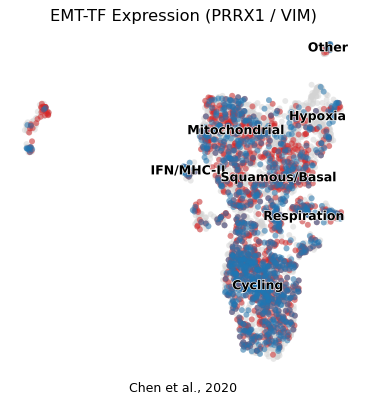

In [ ]:
# save EMT-TF expression figure (expression.pdf): highlight the two most-expressed factors
g_plt = {show[0]:('tab:red',0.5), show[1]:('tab:blue',0.5)}
fig, ax = plt.subplots(1,1, figsize=(5,5))
sc.pl.umap(adata, size=90, alpha=.5, frameon=False, show=False, ax=ax)
for var,(c,thr) in g_plt.items():
    xv = adata[:,var].X; xv = np.asarray(xv.todense()).ravel() if hasattr(xv,'todense') else np.asarray(xv).ravel()
    sub = adata[xv>thr].copy()
    sc.pl.umap(sub, na_color=c, size=90, alpha=.5, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=90, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('EMT-TF Expression (%s / %s)'%(show[0],show[1]), size=13)
ax.text(.5,-.05,'Chen et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()